# Step2 · 2주차: sEMG 전처리와 25차원 특징 추출

**오성빈 | 8개 손동작·팔꿈치 각도 조합 | 모델 학습 전 데이터 준비**

1주차 결과보고서의 연속 기록 64개, 시행 마커 1,920개와 8클래스 설계를 이어받는다.
`pro`는 회내, `extor`는 회외이다. 공개 CSV에는 이미 필터가 적용되어 있으므로 기본 데이터셋에는 추가 필터를 적용하지 않는다.
별도 비교 그림으로 강의의 60 Hz notch(Q=30), 20–450 Hz 4차 Butterworth와 filtfilt를 실습한다.

분석 구간은 **마커 기준 1.5–3.5초라는 강의 가정**이다. 마커와 실제 동작 시작의 정렬은 확인되지 않았으며 논문의 정확한 분석 시작점을 재현했다고 주장하지 않는다.
2주차 강의가 제시한 원자료 기반 특징 추출까지 수행하고 SVM·RF·XGBoost 학습은 3주차에 진행한다.

출처: [원본 데이터 및 설명](https://github.com/TestUser-alt-dev/sEMG-Hand-Gesture-Elbow-Angle-Dataset),
사용자 제공 `Step2_1주차_결과보고서_오성빈.pdf`, `Step2_2주차_강의와실습.pptx`.


In [1]:
from pathlib import Path
import json, inspect
import numpy as np
import pandas as pd
from IPython.display import display, Image
from week2 import build, td_features, split_trials, filter_emg
DATA = Path('data/source/data')
OUT = Path('outputs/week2')
assert DATA.exists(), 'README의 데이터 다운로드 절차를 먼저 실행하세요.'


## 1. 필터와 분석 구간 설정

공개 신호와 추가 필터 결과를 구분한다. 필터 적용 전후라는 표현은 이 노트북의 **추가 필터**에 한정된다.
CSV는 원시 무필터 신호가 아니므로 원래 필터의 효과를 복원하거나 검증할 수 없다.
추가 필터 실험을 선택하더라도 시행마다 독립적으로 처리하고 다음 마커에서 잘라 인접 시행과 표본을 공유하지 않는다.


In [2]:
print(inspect.getsource(filter_emg))

def filter_emg(x):
    """Lecture demonstration; input CSV is already filtered by its publisher."""
    bn, an = iirnotch(60, 30, fs=FS)
    b, a = butter(4, [20, 450], btype="bandpass", fs=FS)
    return filtfilt(b, a, filtfilt(bn, an, x, axis=0), axis=0)



## 2. 시행 단위 분할 — 윈도우 생성보다 먼저

파일 하나에 시행 30개가 들어 있으므로 파일을 시행 하나로 취급하지 않는다.
`파일명 + 마커 순번`으로 시행 ID를 정하고 8클래스 층화 80:20 분할(seed=42)을 먼저 수행한다.
동일 시행의 윈도우 19개는 모두 같은 분할에 들어간다.
같은 피험자·연속 기록의 다른 시행은 양쪽에 존재하므로 이는 **피험자 내 시행 일반화**를 위한 분할이며, 새 피험자에 대한 성능 평가가 아니다.


In [3]:
print(inspect.getsource(split_trials))

def split_trials(trials, seed=42):
    train, test = train_test_split(np.arange(len(trials)), test_size=0.2,
                                   stratify=trials.y, random_state=seed)
    result = trials.copy()
    result['split'] = 'train'
    result.loc[test, 'split'] = 'test'
    assert set(result.loc[train, 'trial_id']).isdisjoint(result.loc[test, 'trial_id'])
    return result



## 3. 특징 함수 전체 코드

순서는 RMS 5채널 → MAV 5채널 → WL 5채널 → ZC 5채널 → SSC 5채널이다.
ZC는 부호 변화와 두 표본 차이 ≥ 0.01을 동시에 요구한다. SSC에는 강의와 동일하게 별도 진폭 문턱값을 적용하지 않는다.
0.01은 원자료 수치 단위 기준 실습 설정이며 기기와 정규화 조건에 독립적인 보편적 기준이 아니다.


In [4]:
print(inspect.getsource(td_features))

def td_features(w, th=0.01):
    """Feature-major order; SSC has no amplitude threshold, as in lecture."""
    w = np.asarray(w, dtype=np.float64)
    if w.shape != (WIN, 5) or not np.isfinite(w).all():
        raise ValueError("Expected finite (200, 5) window")
    rms = np.sqrt(np.mean(w ** 2, axis=0))
    mav = np.mean(np.abs(w), axis=0)
    d = np.diff(w, axis=0)
    wl = np.sum(np.abs(d), axis=0)
    zc = np.sum(((w[:-1] * w[1:]) < 0) & (np.abs(d) >= th), axis=0)
    ssc = np.sum((d[:-1] * d[1:]) < 0, axis=0)
    return np.concatenate([rms, mav, wl, zc, ssc])



## 4. 전체 데이터셋 생성

200 ms는 짧은 구간에서 근활성의 시간영역 특징을 계산하면서 변화도 추적하기 위한 실습 설정이다.
너무 짧은 창의 불안정성과 너무 긴 창의 시간 정보 손실을 절충하지만, 이 길이가 최적이라는 실험은 수행하지 않았다.

50% 중첩은 100 ms 간격으로 특징을 얻어 구간 경계의 변화가 누락되는 것을 줄인다.
인접 창은 상관되어 독립 표본이 아니므로 먼저 시행을 나누고, 3주차 교차검증도 시행 그룹을 보존해야 한다.

2초 × 1,000 Hz = 2,000표본, (2,000−200)/100+1 = 시행당 19개 창.


In [5]:
summary = build(DATA, OUT, segment_start=1500, filter_mode='already-filtered', seed=42)
display({k: summary[k] for k in ['source_commit','n_records','n_trials','n_train_trials',
    'n_test_trials','segment_shape','window_shape','Xtr_shape','Xte_shape']})


{'source_commit': 'cb64ded658b83ae97e6388dd373efad0e97bc47c',
 'n_records': 64,
 'n_trials': 1920,
 'n_train_trials': 1536,
 'n_test_trials': 384,
 'segment_shape': [2000, 5],
 'window_shape': [19, 200, 5],
 'Xtr_shape': [29184, 25],
 'Xte_shape': [7296, 25]}

## 5. 실제 신호·분석 구간·추가 필터 비교 (학습 시행 1개)

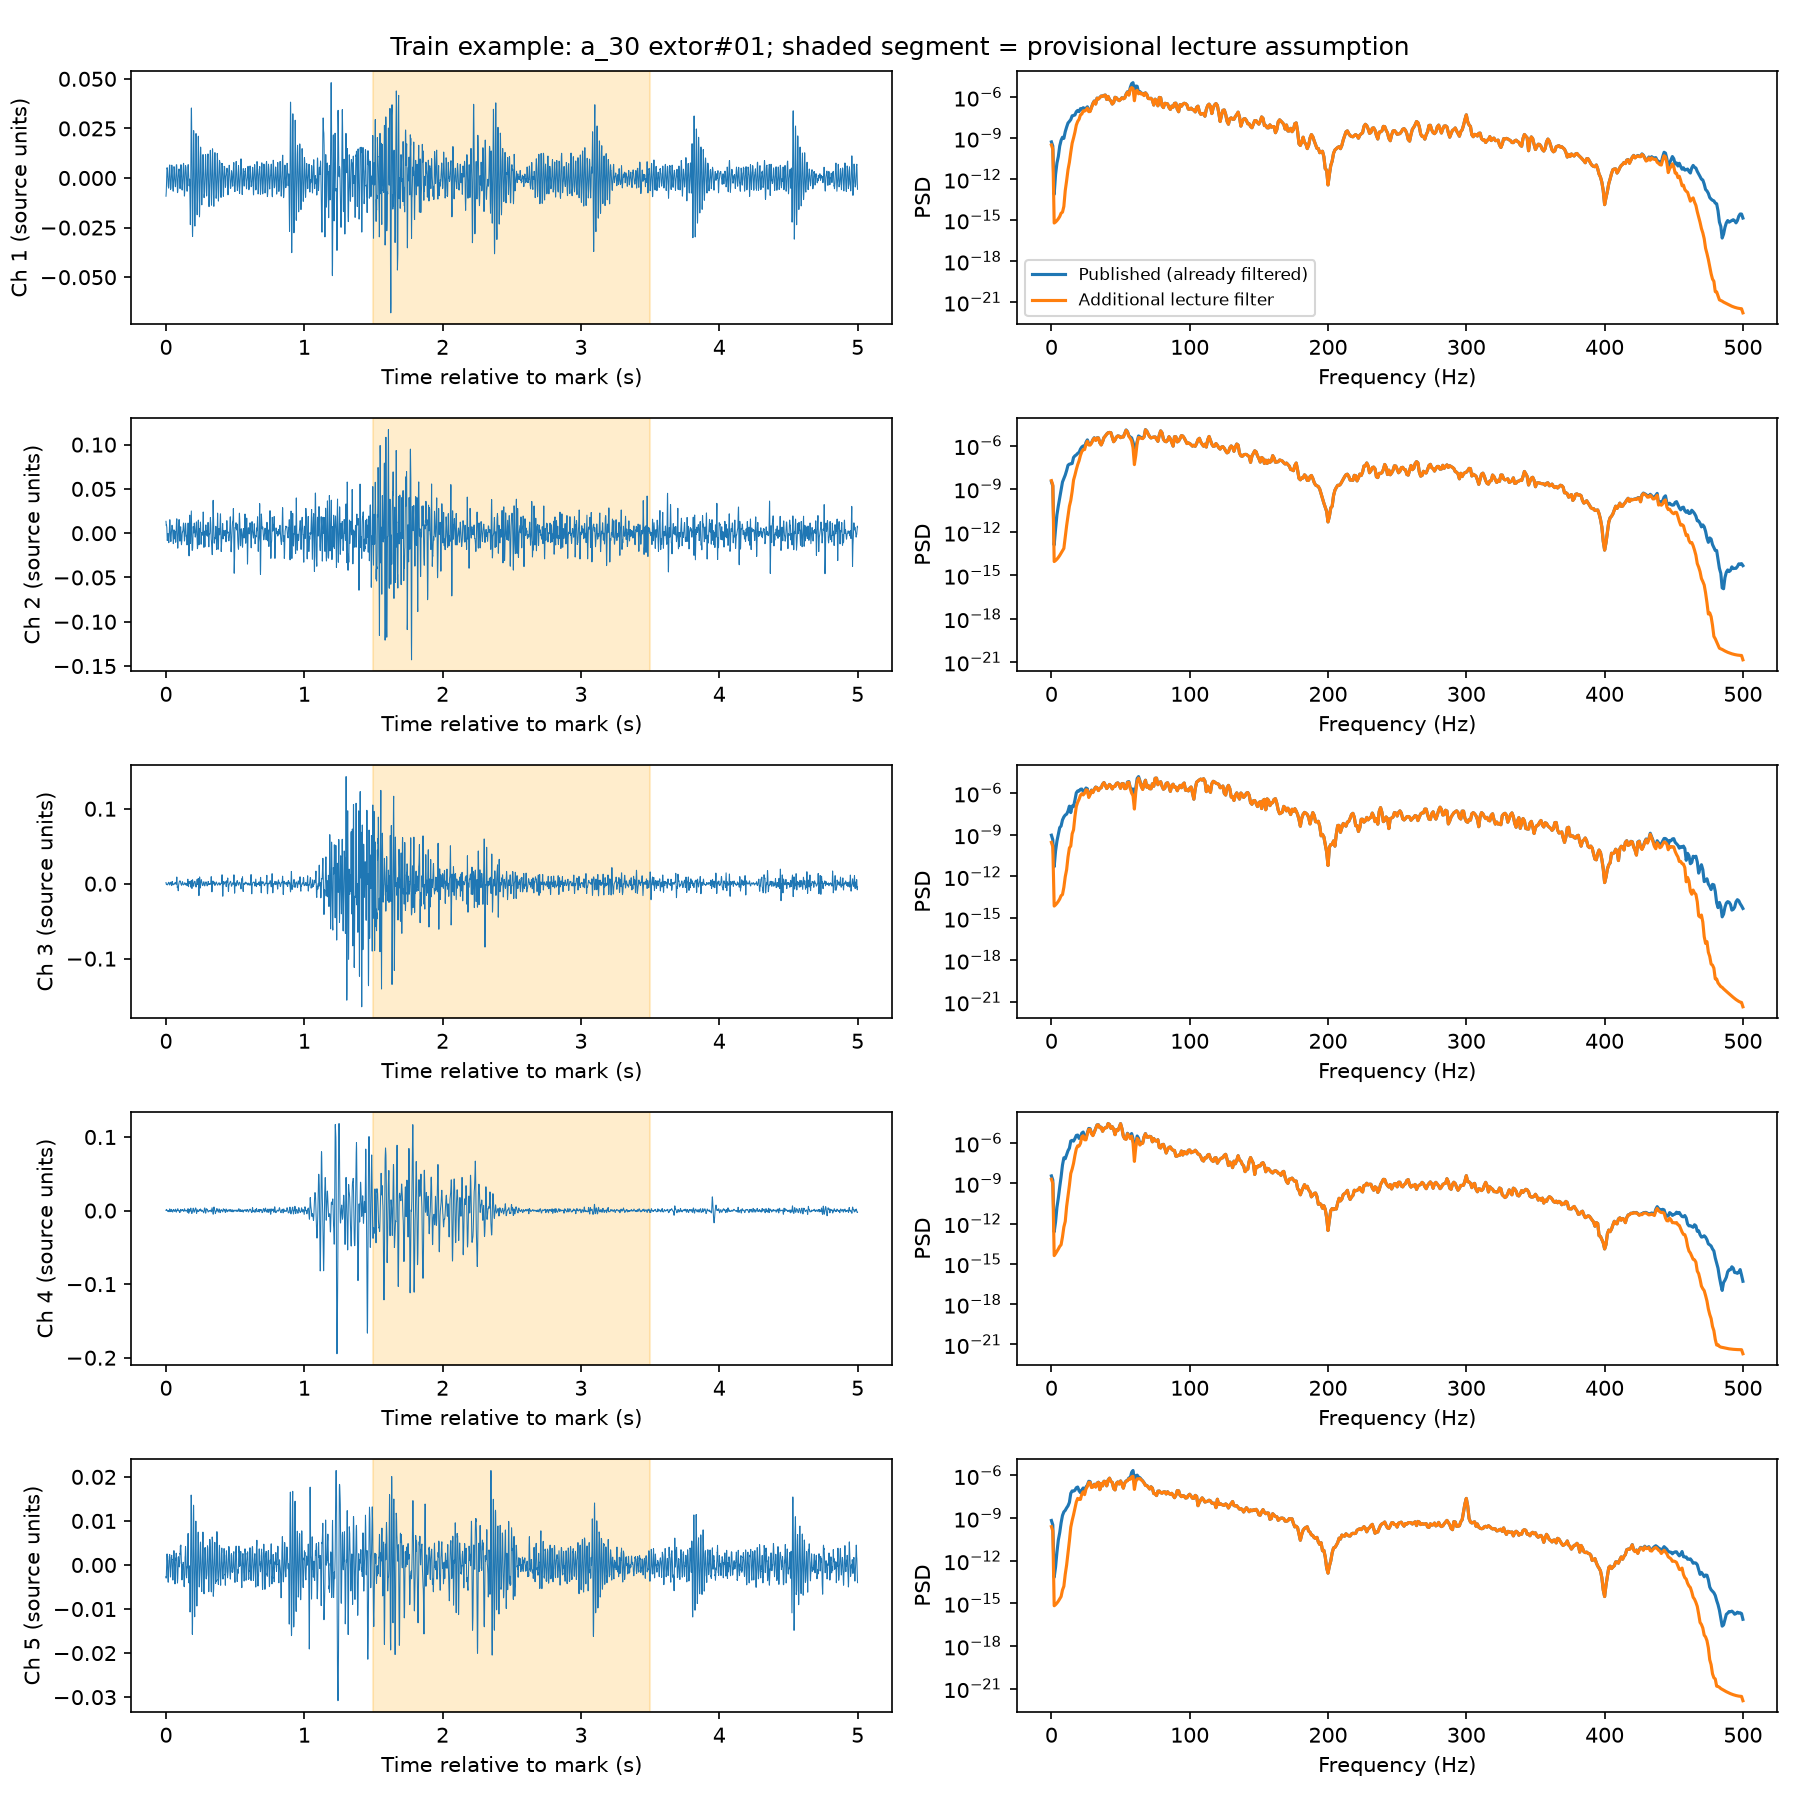

,channel,published_std,additional_filter_std
0,bandpass 1,0.009820,0.008496
1,bandpass 2,0.017901,0.017472
2,bandpass 3,0.019422,0.018874
3,bandpass 4,0.020949,0.019948
4,bandpass 5,0.004824,0.004235


In [6]:
display(Image(filename=str(OUT / 'filter_and_segment.png')))
display(pd.read_csv(OUT / 'filter_std.csv'))

주황색 구간은 잠정 분석 구간이며 실제 동작의 시작·종료를 검증한 표시는 아니다.
PSD와 표준편차는 추가 필터의 수치적 영향을 보여주며 모델 성능 개선의 근거가 아니다.

## 6. 클래스 분포와 ZC 문턱값 비교

In [7]:
display(pd.read_csv(OUT / 'class_distribution.csv'))
display({k: summary[k] for k in ['mean_zc_threshold_zero','mean_zc_threshold_001']})

,label,test,train
0,30_fist,912,3648
1,30_open,912,3648
2,30_pronation,912,3648
3,30_supination,912,3648
4,60_fist,912,3648
5,60_open,912,3648
6,60_pronation,912,3648
7,60_supination,912,3648


{'mean_zc_threshold_zero': 25.64277960526316,
 'mean_zc_threshold_001': 5.906770833333334}

## 7. 저장된 데이터와 표준화 검증

StandardScaler는 학습 특징에만 fit하고 테스트에는 transform만 수행했다.
평균·표준편차는 학습 데이터에만 검증한다. 상수 특징은 표준화 후 0이며 표준편차 1 조건에서 제외한다.


In [8]:
data = np.load(OUT / 'dataset.npz', allow_pickle=False)
assert data['Xtr'].shape == (29184, 25)
assert data['Xte'].shape == (7296, 25)
assert set(data['groups_tr']).isdisjoint(data['groups_te'])
np.testing.assert_allclose(data['Xtr_raw'].mean(0), data['scaler_mean'])
np.testing.assert_allclose((data['Xte_raw'] - data['scaler_mean']) / data['scaler_scale'], data['Xte'])
display({k: summary[k] for k in ['max_abs_train_mean','max_abs_train_std_error',
    'constant_features','overlapping_trial_ids']})
print('검증 완료:', OUT / 'dataset.npz')


{'max_abs_train_mean': 1.845149277033548e-14,
 'max_abs_train_std_error': 1.1801670751765414e-13,
 'constant_features': [],
 'overlapping_trial_ids': 0}

검증 완료: outputs\week2\dataset.npz


## 8. 결과와 3주차 연결

64개 기록 → 1,920개 시행 → 36,480개 윈도우 → 윈도우당 25개 특징을 구성했다.
학습 1,536시행(29,184윈도우), 테스트 384시행(7,296윈도우)이며 모든 클래스의 수가 같다.
같은 시행 ID의 학습·테스트 중복은 0이다. 이 수치는 원자료 검증 및 코드 출력으로 확인한다.

다음 주 SVM·RF·XGBoost 비교 시 `Xtr_raw`와 `groups_tr`로 StratifiedGroupKFold를 구성하고,
각 fold 내부의 Pipeline에서 StandardScaler를 fit해야 한다. 이미 전체 학습 데이터로 표준화한 `Xtr`을 그대로 교차검증에 넣으면 검증 fold의 통계가 유입된다.
테스트 데이터는 최종 평가까지 모델 선택에 사용하지 않는다. 창의 높은 상관성과 피험자·기록 공유를 고려해 성능을 해석하고, 새 피험자 일반화가 목표이면 피험자 단위 분할을 별도로 설계한다.

확인할 사항: 마커 의미와 실제 동작 정렬, 원 논문의 분석 시작점 및 ZC/SSC 정의.
이번 결과는 명시된 강의 가정에 따른 2주차 데이터 준비이며 모델 성능이나 논문 수치 재현 결과를 제시하지 않는다.
